# Notebook 4 — Price & Promotion Optimization

The demand model answers *"how many will we sell?"*. This notebook answers *"what should we charge,
and which offer should we run?"*

For one menu item at one outlet on one day, the optimiser tests **35 candidate strategies**
(5 menu-price levels x 7 offers), converts predicted demand into revenue, cost and profit, and
recommends the strategy with the highest **expected profit**.

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, "../src")
import pricing_engine as engine

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed_restaurant_sales_data.csv.gz")
df["Date"] = pd.to_datetime(df["Date"])
model = joblib.load("../models/xgboost_demand_model.pkl")

print("Dataset loaded:", df.shape)
print("Demand model loaded:", len(model.feature_names_in_), "input features")

Dataset loaded: (174960, 46)
Demand model loaded: 37 input features


## 1. The offers

| Offer | What the customer gets | What it costs the restaurant |
|---|---|---|
| No Promotion | menu price | nothing |
| 5 / 10 / 15 / 20% Discount | that % off the menu price | the lower price |
| Combo Offer | item + add-on at a bundled price (item is 10% cheaper) | the lower price + part of the add-on |
| Buy One Get One | two plates for the price of one | the food cost of the free plate |

In [2]:
promotion_options = engine.PROMOTION_OPTIONS
promotion_parameters = engine.PROMOTION_PARAMETERS

pd.DataFrame(promotion_parameters).T

,discount,price_factor,depth,flag
No Promotion,0.0,1.00,0.00,0.0
5% Discount,5.0,0.95,0.05,1.0
10% Discount,10.0,0.90,0.10,1.0
15% Discount,15.0,0.85,0.15,1.0
20% Discount,20.0,0.80,0.20,1.0
Combo Offer,0.0,0.90,0.10,1.0
Buy One Get One,0.0,1.00,0.50,1.0


### What does an offer cost per unit?

The sales history shows the promotion cost actually booked. Dividing by units sold gives the rule for
each offer: a combo costs about 6% of the item's base price per unit, and BOGO costs one extra plate
(the item's own food cost). Percentage discounts carry no extra cost - the discount is already in the
lower selling price.

So promotion cost is **item-specific**: BOGO on a Rs 55 chai costs far less than BOGO on a Rs 445 biryani.

In [3]:
promos = df[df["Promotion_Flag"] == 1].copy()
promos = promos[promos["Units_Sold"] > 0]
promos["Promo_Cost_Per_Unit"] = promos["Promotion_Cost"] / promos["Units_Sold"]
promos["As_Share_of_Base_Price"] = promos["Promo_Cost_Per_Unit"] / promos["Base_Price"]
promos["As_Share_of_Food_Cost"] = promos["Promo_Cost_Per_Unit"] / promos["Unit_Cost"]

promos.groupby("Promotion_Type")[["Promo_Cost_Per_Unit", "As_Share_of_Base_Price", "As_Share_of_Food_Cost"]].median().round(3)

,Promo_Cost_Per_Unit,As_Share_of_Base_Price,As_Share_of_Food_Cost
Promotion_Type,,,
10% Discount,0.00,0.000,0.000
15% Discount,0.00,0.000,0.000
20% Discount,0.00,0.000,0.000
5% Discount,0.00,0.000,0.000
Buy One Get One,52.19,0.263,1.000
Combo Offer,12.00,0.060,0.229


## 2. The scenario grid and the guardrail

Menu-price levels tested: -10%, -5%, 0, +5%, +10% of the base price. These are the same levels that
appear in the sales history, so the model is never asked about a price it has not seen.

**Guardrail - no fake discounts.** An offer is only allowed on a menu price at or below the base price.
Raising the menu price by 10% and then advertising "10% off" would be a fake discount, so those 12
combinations are excluded. That leaves 23 valid strategies out of 35.

In [4]:
grid = engine.scenario_grid(base_price=400)
print("Candidate strategies:", len(grid), "| valid:", int(grid["Valid"].sum()), "| excluded by the guardrail:", int((~grid["Valid"]).sum()))

grid.pivot(index="Promotion_Type", columns="Price_Adjustment", values="Valid").loc[promotion_options]

Candidate strategies: 35 | valid: 23 | excluded by the guardrail: 12


Price_Adjustment,-0.10,-0.05,0.00,0.05,0.10
Promotion_Type,,,,,
No Promotion,True,True,True,True,True
5% Discount,True,True,True,False,False
10% Discount,True,True,True,False,False
15% Discount,True,True,True,False,False
20% Discount,True,True,True,False,False
Combo Offer,True,True,True,False,False
Buy One Get One,True,True,True,False,False


## 3. Worked example

**Butter Chicken at outlet R01 (Delhi, casual dining) on a normal Tuesday.**

`build_context` describes the situation being priced: the item's costs and usual demand, the
competitor's regular price, and the conditions expected on that date (weekday, festival, typical
footfall and weather).

In [5]:
ITEM, OUTLET = "M06", "R01"
weekday_date = pd.Timestamp("2026-10-06")   # Tuesday, after the sales history ends

history = df[(df["Item_ID"] == ITEM) & (df["Outlet_ID"] == OUTLET)]
context = engine.build_context(history, weekday_date)

pd.Series({k: context[k] for k in ["Item_Name", "Category", "Outlet_ID", "City", "Outlet_Type", "Day_of_Week", "Festival",
                                    "Base_Price", "Unit_Cost", "Overhead_Cost", "Competitor_Price",
                                    "Footfall_Index", "Temperature", "Rainfall", "Avg_Item_Demand"]})

Item_Name           Butter Chicken
Category               Main Course
Outlet_ID                      R01
City                         Delhi
Outlet_Type          Casual Dining
Day_of_Week                Tuesday
Festival               No Festival
Base_Price                   415.0
Unit_Cost               143.082143
Overhead_Cost          6709.124643
Competitor_Price             429.0
Footfall_Index            0.833194
Temperature              25.554098
Rainfall                  0.690164
Avg_Item_Demand          58.238683
dtype: object

### Profit calculation

For every strategy:

```
Revenue          = price the customer pays x predicted units
Food cost        = unit food cost x predicted units
Promotion cost   = promotion cost per unit x predicted units
Total cost       = food cost + promotion cost + overhead
Expected profit  = revenue - total cost
```

In [6]:
results = engine.optimize(model, context)

print("Strategies evaluated:", len(results), "| valid:", int(results["Valid"].sum()))
results[results["Valid"]].head(10).round(2)

Strategies evaluated: 35 | valid: 23


,Price_Adjustment,Menu_Price,Promotion_Type,Selling_Price,Predicted_Units,Revenue,Food_Cost,Promotion_Cost,Overhead_Cost,Total_Cost,Expected_Profit,Valid
0,0.00,415.0,Combo Offer,374.0,56.35,21075.33,8062.84,1403.14,6709.12,16175.11,4900.22,True
1,-0.05,394.0,Combo Offer,355.0,58.94,20925.26,8433.89,1467.72,6709.12,16610.73,4314.53,True
2,0.10,457.0,No Promotion,457.0,35.11,16045.09,5023.56,0.00,6709.12,11732.68,4312.41,True
3,0.00,415.0,10% Discount,374.0,46.40,17353.02,6638.79,0.00,6709.12,13347.91,4005.10,True
4,0.05,436.0,No Promotion,436.0,36.48,15905.98,5219.87,0.00,6709.12,11928.99,3976.99,True
5,0.00,415.0,20% Discount,332.0,56.45,18742.51,8077.47,0.00,6709.12,14786.59,3955.92,True
6,-0.10,374.0,Combo Offer,337.0,63.05,21246.69,9020.84,1569.86,6709.12,17299.82,3946.87,True
7,0.00,415.0,5% Discount,394.0,42.27,16653.16,6047.64,0.00,6709.12,12756.76,3896.39,True
8,-0.05,394.0,5% Discount,374.0,45.86,17150.50,6561.31,0.00,6709.12,13270.43,3880.06,True
9,0.00,415.0,15% Discount,353.0,50.15,17702.90,7175.55,0.00,6709.12,13884.68,3818.23,True


In [7]:
best_strategy = results.iloc[0]
current = results[(results["Price_Adjustment"] == 0) & (results["Promotion_Type"] == "No Promotion")].iloc[0]

print("OPTIMAL PRICING & PROMOTION STRATEGY")
print("=" * 45)
print("Item             :", context["Item_Name"], "at", OUTLET, "on", weekday_date.strftime("%A %d %b %Y"))
print("Promotion        :", best_strategy["Promotion_Type"])
print("Menu price       : Rs", round(best_strategy["Menu_Price"], 2), f"({best_strategy['Price_Adjustment']:+.0%} vs base)")
print("Customer pays    : Rs", round(best_strategy["Selling_Price"], 2))
print("Predicted demand :", round(best_strategy["Predicted_Units"], 1), "units")
print("Expected revenue : Rs", round(best_strategy["Revenue"], 2))
print("Expected cost    : Rs", round(best_strategy["Total_Cost"], 2))
print("Expected profit  : Rs", round(best_strategy["Expected_Profit"], 2))
print()
print("Base price, no offer -> profit Rs", round(current["Expected_Profit"], 2))
print(f"Uplift from the recommendation: Rs {best_strategy['Expected_Profit'] - current['Expected_Profit']:.2f} "
      f"({(best_strategy['Expected_Profit'] / current['Expected_Profit'] - 1) * 100:+.1f}%)")

OPTIMAL PRICING & PROMOTION STRATEGY
Item             : Butter Chicken at R01 on Tuesday 06 Oct 2026
Promotion        : Combo Offer
Menu price       : Rs 415.0 (+0% vs base)
Customer pays    : Rs 374.0
Predicted demand : 56.4 units
Expected revenue : Rs 21075.33
Expected cost    : Rs 16175.11
Expected profit  : Rs 4900.22

Base price, no offer -> profit Rs 3631.54
Uplift from the recommendation: Rs 1268.68 (+34.9%)


### Best menu price for each offer

In [8]:
promotion_comparison = engine.best_by_promotion(results).round(2)
promotion_comparison

,Best_Menu_Price,Customer_Pays,Predicted_Units,Revenue,Promotion_Cost,Total_Cost,Expected_Profit
Promotion_Type,,,,,,,
Combo Offer,415.0,374.0,56.35,21075.33,1403.14,16175.11,4900.22
No Promotion,457.0,457.0,35.11,16045.09,0.00,11732.68,4312.41
10% Discount,415.0,374.0,46.40,17353.02,0.00,13347.91,4005.10
20% Discount,415.0,332.0,56.45,18742.51,0.00,14786.59,3955.92
5% Discount,415.0,394.0,42.27,16653.16,0.00,12756.76,3896.39
15% Discount,415.0,353.0,50.15,17702.90,0.00,13884.68,3818.23
Buy One Get One,415.0,415.0,57.22,23745.16,8186.77,23082.66,662.50


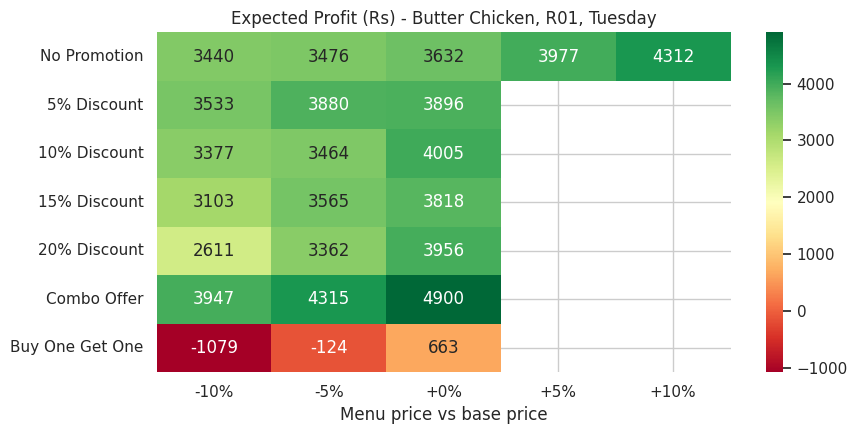

In [9]:
pivot = results[results["Valid"]].pivot(index="Promotion_Type", columns="Price_Adjustment", values="Expected_Profit").loc[promotion_options]
pivot.columns = [f"{c:+.0%}" for c in pivot.columns]

plt.figure(figsize=(9, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn")
plt.title(f"Expected Profit (Rs) - {context['Item_Name']}, {OUTLET}, {weekday_date.strftime('%A')}")
plt.xlabel("Menu price vs base price")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Higher demand is not higher profit

The strategy that sells the most units is rarely the one that earns the most.

In [10]:
valid = results[results["Valid"]]
most_units = valid.sort_values("Predicted_Units", ascending=False).iloc[0]

pd.DataFrame({
    "Highest demand": most_units[["Promotion_Type", "Menu_Price", "Selling_Price", "Predicted_Units", "Revenue", "Expected_Profit"]],
    "Highest profit": best_strategy[["Promotion_Type", "Menu_Price", "Selling_Price", "Predicted_Units", "Revenue", "Expected_Profit"]],
})

,Highest demand,Highest profit
Promotion_Type,Buy One Get One,Combo Offer
Menu_Price,374.0,415.0
Selling_Price,374.0,374.0
Predicted_Units,64.095421,56.351151
Revenue,23971.687393,21075.330292
Expected_Profit,-1079.257571,4900.218633


### What the guardrail prevents

Without the guardrail the highest-profit row can be an offer on a raised menu price.

In [11]:
unconstrained = results.sort_values("Expected_Profit", ascending=False).iloc[0]
print("Best strategy WITHOUT the guardrail:", unconstrained["Promotion_Type"], "at", f"{unconstrained['Price_Adjustment']:+.0%}",
      "menu price -> profit Rs", round(unconstrained["Expected_Profit"], 2), "| valid:", bool(unconstrained["Valid"]))
print("Best strategy WITH the guardrail   :", best_strategy["Promotion_Type"], "at", f"{best_strategy['Price_Adjustment']:+.0%}",
      "menu price -> profit Rs", round(best_strategy["Expected_Profit"], 2))

Best strategy WITHOUT the guardrail: Combo Offer at +10% menu price -> profit Rs 5780.79 | valid: False
Best strategy WITH the guardrail   : Combo Offer at +0% menu price -> profit Rs 4900.22


## 4. Same item, different day

The right strategy depends on the day. The same item is optimised for a Tuesday, a Saturday and Diwali.

In [12]:
days = {"Tuesday": "2026-10-06", "Saturday": "2026-10-10", "Diwali": "2026-11-08"}
rows = []
for label, day in days.items():
    ctx = engine.build_context(history, pd.Timestamp(day))
    res = engine.optimize(model, ctx)
    top = res.iloc[0]
    base = res[(res["Price_Adjustment"] == 0) & (res["Promotion_Type"] == "No Promotion")].iloc[0]
    rows.append({
        "Day": label, "Date": day, "Expected_Footfall": round(ctx["Footfall_Index"], 2),
        "Recommended_Offer": top["Promotion_Type"], "Menu_Price": top["Menu_Price"], "Customer_Pays": top["Selling_Price"],
        "Predicted_Units": round(top["Predicted_Units"], 1), "Expected_Profit": round(top["Expected_Profit"], 0),
        "Profit_at_Base_Price": round(base["Expected_Profit"], 0),
        "Uplift_%": round((top["Expected_Profit"] / base["Expected_Profit"] - 1) * 100, 1),
    })
pd.DataFrame(rows)

,Day,Date,Expected_Footfall,Recommended_Offer,Menu_Price,Customer_Pays,Predicted_Units,Expected_Profit,Profit_at_Base_Price,Uplift_%
0,Tuesday,2026-10-06,0.83,Combo Offer,415.0,374.0,56.4,4900.0,3632.0,34.9
1,Saturday,2026-10-10,1.21,No Promotion,457.0,457.0,59.4,11923.0,11094.0,7.5
2,Diwali,2026-11-08,1.23,No Promotion,436.0,436.0,61.3,11250.0,10604.0,6.1


## 5. Whole-menu optimisation

The optimiser is now run for **every menu item at every outlet** (240 item-outlet pairs) for a Tuesday
and a Saturday. The comparison point is selling at the base price with no offer.

In [13]:
def optimise_menu(date):
    rows = []
    for (item, outlet), item_history in df.groupby(["Item_ID", "Outlet_ID"]):
        ctx = engine.build_context(item_history, date)
        res = engine.optimize(model, ctx)
        top = res.iloc[0]
        base = res[(res["Price_Adjustment"] == 0) & (res["Promotion_Type"] == "No Promotion")].iloc[0]
        rows.append({
            "Date": date.date(), "Day": date.strftime("%A"), "Item_ID": item, "Item_Name": ctx["Item_Name"], "Category": ctx["Category"],
            "Outlet_ID": outlet, "Outlet_Type": ctx["Outlet_Type"], "Base_Price": ctx["Base_Price"],
            "Recommended_Offer": top["Promotion_Type"], "Price_Adjustment": top["Price_Adjustment"],
            "Recommended_Menu_Price": top["Menu_Price"], "Customer_Pays": top["Selling_Price"],
            "Predicted_Units": top["Predicted_Units"], "Expected_Profit": top["Expected_Profit"],
            "Profit_at_Base_Price": base["Expected_Profit"],
        })
    return pd.DataFrame(rows)

menu_plan = pd.concat([optimise_menu(pd.Timestamp("2026-10-06")), optimise_menu(pd.Timestamp("2026-10-10"))], ignore_index=True)
menu_plan["Profit_Uplift"] = menu_plan["Expected_Profit"] - menu_plan["Profit_at_Base_Price"]

print("Item-outlet-day combinations optimised:", len(menu_plan))
menu_plan.head().round(2)

Item-outlet-day combinations optimised: 480


,Date,Day,Item_ID,Item_Name,Category,Outlet_ID,Outlet_Type,Base_Price,Recommended_Offer,Price_Adjustment,Recommended_Menu_Price,Customer_Pays,Predicted_Units,Expected_Profit,Profit_at_Base_Price,Profit_Uplift
0,2026-10-06,Tuesday,M01,Paneer Tikka,Starters,R01,Casual Dining,300.0,15% Discount,0.0,300.0,255.0,38.01,3242.62,2419.43,823.20
1,2026-10-06,Tuesday,M01,Paneer Tikka,Starters,R02,Quick Service,270.0,15% Discount,0.0,270.0,230.0,30.22,2075.52,1694.39,381.13
2,2026-10-06,Tuesday,M01,Paneer Tikka,Starters,R03,Casual Dining,285.0,15% Discount,0.0,285.0,242.0,31.99,2349.12,1906.76,442.36
3,2026-10-06,Tuesday,M01,Paneer Tikka,Starters,R04,Casual Dining,320.0,10% Discount,0.0,320.0,288.0,41.77,3852.29,3070.98,781.31
4,2026-10-06,Tuesday,M01,Paneer Tikka,Starters,R05,Cloud Kitchen,260.0,15% Discount,0.0,260.0,221.0,26.05,2173.87,1653.40,520.47


In [14]:
summary = menu_plan.groupby("Day").agg(
    Profit_at_Base_Price=("Profit_at_Base_Price", "sum"),
    Optimised_Profit=("Expected_Profit", "sum"),
)
summary["Uplift_Rs"] = summary["Optimised_Profit"] - summary["Profit_at_Base_Price"]
summary["Uplift_%"] = summary["Uplift_Rs"] / summary["Profit_at_Base_Price"] * 100
summary.loc[["Tuesday", "Saturday"]].round(1)

,Profit_at_Base_Price,Optimised_Profit,Uplift_Rs,Uplift_%
Day,,,,
Tuesday,379397.6,465158.0,85760.5,22.6
Saturday,692145.2,732307.7,40162.6,5.8


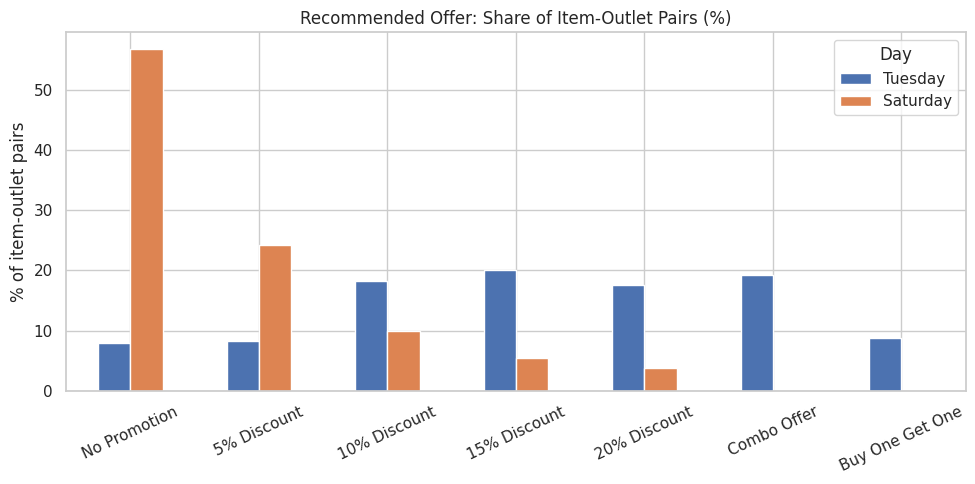

Day,Tuesday,Saturday
Recommended_Offer,,
No Promotion,7.9,56.7
5% Discount,8.3,24.2
10% Discount,18.3,10.0
15% Discount,20.0,5.4
20% Discount,17.5,3.8
Combo Offer,19.2,0.0
Buy One Get One,8.8,0.0


In [15]:
offer_mix = (pd.crosstab(menu_plan["Recommended_Offer"], menu_plan["Day"], normalize="columns") * 100).round(1)
offer_mix = offer_mix.reindex(promotion_options).fillna(0)[["Tuesday", "Saturday"]]

offer_mix.plot(kind="bar", figsize=(10, 5))
plt.title("Recommended Offer: Share of Item-Outlet Pairs (%)")
plt.ylabel("% of item-outlet pairs")
plt.xlabel("")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
offer_mix

In [16]:
tuesday = menu_plan[menu_plan["Day"] == "Tuesday"]
(pd.crosstab(tuesday["Category"], tuesday["Recommended_Offer"], normalize="index") * 100).round(0).reindex(columns=promotion_options).fillna(0)

Recommended_Offer,No Promotion,5% Discount,10% Discount,15% Discount,20% Discount,Combo Offer,Buy One Get One
Category,,,,,,,
Beverages,0.0,0.0,12.0,15.0,28.0,0.0,45.0
Breads,40.0,22.0,28.0,5.0,5.0,0.0,0.0
Desserts,2.0,0.0,22.0,42.0,28.0,0.0,5.0
Main Course,2.0,15.0,12.0,12.0,2.0,55.0,0.0
Rice & Biryani,2.0,12.0,15.0,8.0,0.0,60.0,2.0
Starters,0.0,0.0,20.0,38.0,42.0,0.0,0.0


In [17]:
price_mix = (pd.crosstab(menu_plan["Price_Adjustment"], menu_plan["Day"], normalize="columns") * 100).round(1)[["Tuesday", "Saturday"]]
price_mix.index = [f"{i:+.0%}" for i in price_mix.index]
print("Recommended menu-price level, share of item-outlet pairs (%):")
price_mix

Recommended menu-price level, share of item-outlet pairs (%):


Day,Tuesday,Saturday
-10%,3.8,8.8
-5%,19.2,7.9
+0%,70.4,32.9
+5%,2.5,11.2
+10%,4.2,39.2


## 6. Save the outputs

In [18]:
promotion_comparison.to_csv("../data/promotion_optimization_results.csv")
results.round(4).to_csv("../data/all_optimization_scenarios.csv", index=False)
menu_plan.round(2).to_csv("../data/menu_optimization_summary.csv", index=False)

executive_summary = pd.DataFrame({
    "Metric": ["Menu Item", "Outlet", "Date", "Best Promotion", "Recommended Menu Price", "Customer Pays",
               "Predicted Units", "Expected Revenue", "Expected Total Cost", "Expected Profit", "Profit at Base Price (No Offer)"],
    "Value": [context["Item_Name"], OUTLET, str(weekday_date.date()), best_strategy["Promotion_Type"],
              round(best_strategy["Menu_Price"], 2), round(best_strategy["Selling_Price"], 2),
              round(best_strategy["Predicted_Units"], 2), round(best_strategy["Revenue"], 2),
              round(best_strategy["Total_Cost"], 2), round(best_strategy["Expected_Profit"], 2), round(current["Expected_Profit"], 2)],
})
executive_summary.to_csv("../data/optimization_executive_summary.csv", index=False)

optimization_config = {
    "promotion_options": engine.PROMOTION_OPTIONS,
    "promotion_parameters": engine.PROMOTION_PARAMETERS,
    "price_adjustments": engine.PRICE_ADJUSTMENTS,
    "combo_addon_cost_rate": engine.COMBO_ADDON_COST_RATE,
}
joblib.dump(optimization_config, "../models/optimization_config.pkl")

print("Saved: promotion_optimization_results.csv, all_optimization_scenarios.csv,")
print("       menu_optimization_summary.csv, optimization_executive_summary.csv, optimization_config.pkl")
executive_summary

Saved: promotion_optimization_results.csv, all_optimization_scenarios.csv,
       menu_optimization_summary.csv, optimization_executive_summary.csv, optimization_config.pkl


,Metric,Value
0,Menu Item,Butter Chicken
1,Outlet,R01
2,Date,2026-10-06
3,Best Promotion,Combo Offer
4,Recommended Menu Price,415.0
5,Customer Pays,374.0
6,Predicted Units,56.35
7,Expected Revenue,21075.33
8,Expected Total Cost,16175.11
9,Expected Profit,4900.22


## 7. Findings

In [19]:
tue, sat = summary.loc["Tuesday"], summary.loc["Saturday"]
no_offer_sat = offer_mix.loc["No Promotion", "Saturday"]
no_offer_tue = offer_mix.loc["No Promotion", "Tuesday"]
cat_offer = pd.crosstab(tuesday["Category"], tuesday["Recommended_Offer"]).idxmax(axis=1)

print(f"1. Across the whole menu the optimiser lifts expected profit by {tue['Uplift_%']:.1f}% on a Tuesday "
      f"and {sat['Uplift_%']:.1f}% on a Saturday, versus selling at base price with no offer.")
print(f"2. Offers belong on slow days: 'No Promotion' is recommended for {no_offer_tue:.0f}% of item-outlet pairs on Tuesday "
      f"but {no_offer_sat:.0f}% on Saturday.")
print("3. The most recommended Tuesday offer by category: " + "; ".join(f"{c} -> {o}" for c, o in cat_offer.items()) + ".")
print(f"4. On Saturday {price_mix.loc[['+5%', '+10%'], 'Saturday'].sum():.0f}% of item-outlet pairs can carry a higher menu price; "
      f"on Tuesday only {price_mix.loc[['+5%', '+10%'], 'Tuesday'].sum():.0f}%.")
print("5. The highest-demand strategy is not the highest-profit strategy - the optimiser ranks by expected profit.")

1. Across the whole menu the optimiser lifts expected profit by 22.6% on a Tuesday and 5.8% on a Saturday, versus selling at base price with no offer.
2. Offers belong on slow days: 'No Promotion' is recommended for 8% of item-outlet pairs on Tuesday but 57% on Saturday.
3. The most recommended Tuesday offer by category: Beverages -> Buy One Get One; Breads -> No Promotion; Desserts -> 15% Discount; Main Course -> Combo Offer; Rice & Biryani -> Combo Offer; Starters -> 20% Discount.
4. On Saturday 50% of item-outlet pairs can carry a higher menu price; on Tuesday only 7%.
5. The highest-demand strategy is not the highest-profit strategy - the optimiser ranks by expected profit.
